Material for the book [Probability and Statistics for Data Science](https://a.co/d/cAss9mO). A free preprint, videos, code, slides and solutions to exercises are available at https://www.ps4ds.net/

Analysis of the penguins dataset in the seaborn Python package, which contains measurements from individuals belonging to three penguin species in the Palmer Archipelago, Antarctica.\
Topics and relevant videos: [Principal component analysis](https://www.youtube.com/watch?v=hPM7F2CP9vQ) 

Author: Carlos Fernandez-Granda

In [10]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler

# Load dataset & remove missing values
df = sns.load_dataset("penguins").dropna()
features = ['bill_length_mm', 'bill_depth_mm', 'flipper_length_mm', 'body_mass_g']

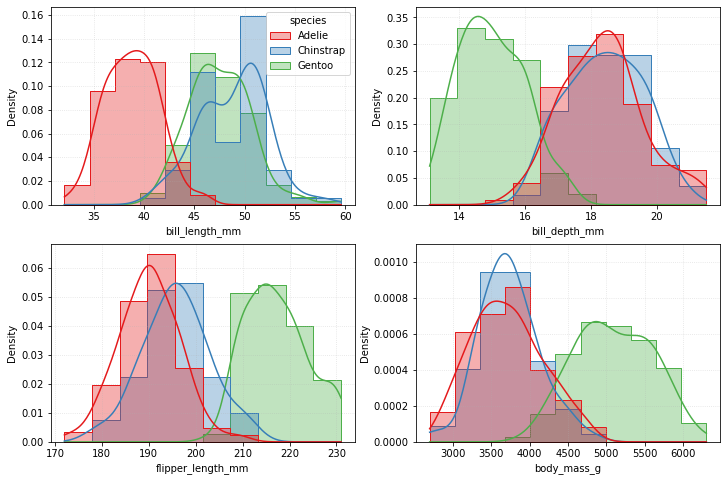

In [11]:
# Individual features
fig1, axes1 = plt.subplots(2, 2, figsize=(12, 8))
axes1 = axes1.flatten()

for i, feat in enumerate(features):
    sns.histplot(
        data=df, 
        x=feat, 
        hue='species', 
        palette='Set1',
        element='step', 
        stat='density', 
        common_norm=False,
        kde=True, 
        ax=axes1[i], 
        alpha=0.35, 
        legend=(i == 0)  # Place legend on the first plot
    )
    axes1[i].set_ylabel('Density', fontsize=10)
    axes1[i].grid(True, linestyle=':', alpha=0.4)

In [12]:
# Standardize features and perform PCA
scaler = StandardScaler()
X_scaled = scaler.fit_transform(df[features])
pca = PCA()

pca = PCA()
pc_scores = pca.fit_transform(X_scaled)
df['PC1'] = pc_scores[:, 0]
pcs = [f'PC{i+1}' for i in range(len(features))]

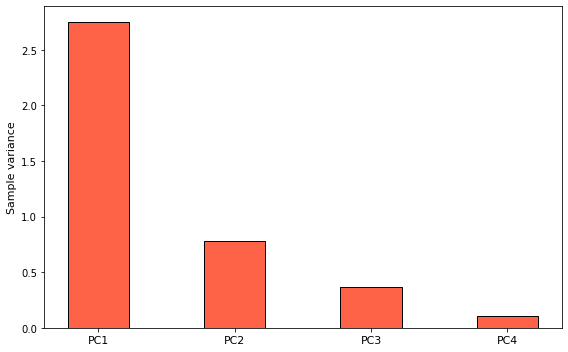

In [13]:
# Plot eigenvalues
eigenvalues = pca.explained_variance_

fig2, ax1 = plt.subplots(figsize=(8, 5))
x_pos = np.arange(len(pcs))

# Eigenvalues bar plot
bars = ax1.bar(
    x_pos, eigenvalues, 
    color='tomato', edgecolor='black', alpha=1, width=0.45)
ax1.set_ylabel('Sample variance', fontsize=11)
#ax1.set_xlabel('Principal compo', fontsize=11)
ax1.set_xticks(x_pos)
ax1.set_xticklabels(pcs, fontsize=11)
plt.tight_layout()

In [14]:
# First principal component
print(pd.Series(pca.components_[0], index=features).round(3))

bill_length_mm       0.454
bill_depth_mm       -0.399
flipper_length_mm    0.577
body_mass_g          0.550
dtype: float64


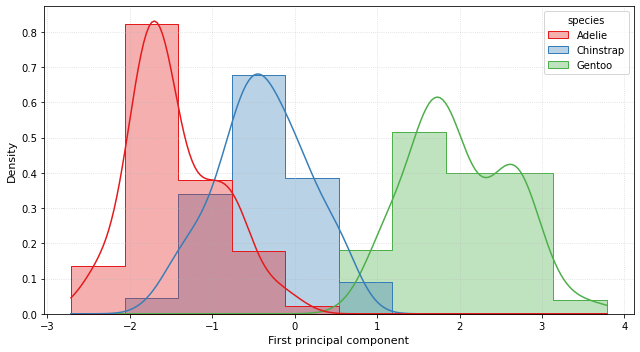

In [15]:
plt.figure(figsize=(9, 5))
sns.histplot(
    data=df,
    x='PC1',
    hue='species',
    palette='Set1',
    element='step',
    stat='density',
    common_norm=False,
    kde=True,
    alpha=0.35
)
plt.xlabel('First principal component', fontsize=11)
plt.ylabel('Density', fontsize=11)
plt.grid(True, linestyle=':', alpha=0.5)
plt.tight_layout()

plt.show()